# 2D DC Resistivity data collection: Addendum
------
* Due Date: November 17, 2026 (unchanged)


## Objectives:
* Plot pseudosections of our data over the archaeological wall using the corrected electrode positions
* Crop the pseudosections to the shallow part where the walls are, and adjust the colour scale to make the anomalies easier to see
* Learn to "sniff test" a data set for artefacts that come from how the data were recorded or exported


## Background
The Terrameter exports each survey in more than one format. The `.txt` file you have been using has the most information (current, Var(%), electrode test results), but it writes electrode positions to only **one decimal place**: 0.25 m becomes 0.2 or 0.3, and 0.75 m becomes 0.8. With our 0.25 m electrode spacing, that makes some electrode pairs look up to 0.05 m closer together or farther apart than they really were (which, as we know from lecture, is a bit of a problem when we're calculating apparent resistivity... see below).

Since apparent resistivity depends on the geometric factor, which depends on those distances, we can't really use these rounded positions and expect good results. If you were to use the rounded positions, the errors repeat every four electrodes (every 1 m) and sortof 'paint' false vertical stripes across the top of the pseudosection. These stripes are not real.

The `.dat` file (a format used by inversion software also found in the OneDrive) stores positions to two decimal places, so it avoids this problem. It contains the same readings and the same V/I values as the `.txt` file.

**If you already made pseudosections from the `.txt` files, please replot them with this notebook.**
**It'll make a lot more sense**


### Data files
All files are in the `data2026` folder:

| File | What it is |
|---|---|
| `DipoleDipole_1-2023-03-08-123242.dat` | Dipole-dipole survey, 1980 readings. **Use this to plot.** |
| `Wenner_1-2023-03-08-123545.dat` | Wenner survey, 651 readings. **Use this to plot.** |
| `DipoleDipole_1-2023-03-08-123312.txt` | Dipole-dipole, full Terrameter export (current, Var(%), electrode test) |
| `Wenner_1-2023-03-08-123603.txt` | Wenner, full Terrameter export |
| `Lab10GPSPoints.csv` | Emlid positions of electrodes 1, 17, 33, 49 and 64 |

* The dates in the file names and headers say 2023. The Terrameter's clock was not set (pretty standard practice)), but these are our data from November 10, 2026.
* Electrode 1 (x = 0 m) is at the end of the line closest to the Guggenheim building; electrode 64 (x = 15.75 m) is closest to the Green Center.
* All 64 electrodes passed the electrode test (see the end of the `.txt` files).
* The 2023 example over the dipping slab (0.5 m spacing) is not affected, because rounding to one decimal place does not change any of its positions. **We used a denser spacing so have to switch it up!**


## Task
1. Run the cells below to load the `.dat` file for each survey over the archaeological wall.
2. Plot a pseudosection of apparent resistivity for the dipole-dipole and the Wenner survey.
3. Adjust the depth and colour scale until you can see the anomalies clearly.
4. Use these pseudosections, in place of any made from the `.txt` files, in your Lab 10 report.


## Deliverables
**There are no new deliverables.** This notebook is to help with plotting. **Your Lab 10 report and its rubric are unchanged;** only the pseudosections of the archaeological wall should come from this notebook.


## Plotting pseudosections
As in Lab 10, we use utilities in `SimPEG` (an open source geophysical simulation and inversion package) to plot the pseudosections.

> **REMEMBER! IMPORTANT: BINDER DOES NOT SAVE YOUR WORK.**
> Binder shuts down after about ~10 minutes of inactivity. When it does, everything you have done will be gone. To protect your work:
> * Download your notebook often: **File > Download** (it saves as a `.ipynb` file).
> * Copy your answers and save your figures into your report as you go. Try not to wait until the end because you might lose all you progress!
> * To pick up where you left off, open a fresh Binder session and drag your downloaded `.ipynb` file into the file browser on the left.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import pandas as pd
import simpeg.electromagnetics.static.utils as static_utils

# SimPEG warns that it re-ordered the electrodes; that is expected, and we sort the data to match below
import warnings
warnings.filterwarnings('ignore', message='Ordering of ABMN locations changed')

## Dipole-dipole survey over the archaeological wall
### Step 1: load the `.dat` file
Each data line in a `.dat` file looks like this:

`4  A(x) A(z)  B(x) B(z)  M(x) M(z)  N(x) N(z)  V/I`

The first number (4) is the number of electrodes in the reading, then come the x and z positions of A, B, M and N (in m), and last is the normalized voltage V/I (in ohms). The cell below reads these columns, the same way we read the `.txt` columns in Lab 10.

In [2]:
filename = 'data2026/DipoleDipole_1-2023-03-08-123242.dat'

with open(filename) as f:
    lines = f.readlines()
n_data = int(lines[6])     # line 7 of the file gives the number of readings
d = np.array([line.split() for line in lines[9:9 + n_data]], dtype=float)  # readings start on line 10
print(n_data, 'readings')

A = d[:, 1:3]    # (x, z) of the A electrode for every reading, an (n_data, 2) array
B = d[:, 3:5]
M = d[:, 5:7]
N = d[:, 7:9]

# Create a simpeg "survey" from these locations:
# The survey will not necessarily be in the same order as the
# ABMN values you supplied, but it will helpfully also return an array you
# can use to re-arrange your data that corresponds to the survey.
survey, sort_index = static_utils.generate_survey_from_abmn_locations(
    locations_a=A, locations_b=B, locations_m=M, locations_n=N,
    data_type='volt', output_sorting=True
)

norm_v = d[:, 9][sort_index]   # the normalized voltage column (V/I, in ohms)

1980 readings


### Step 2: plot the pseudosections
These are the same four plots as in Lab 10: normalized voltage, then apparent resistivity, each on a linear and then a log color scale.

Text(0.5, 1.0, 'Wall, dipole-dipole: normalized voltage')

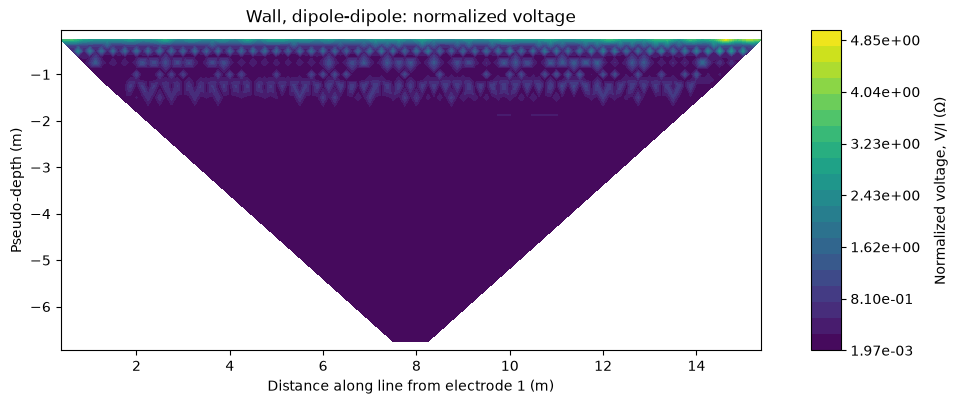

In [3]:
# can plot the normalized voltages
ax, im = static_utils.plot_pseudosection(
    survey, norm_v, cbar_label=r'Normalized voltage, V/I ($\Omega$)',
    contourf_opts={'levels':20}
)
ax.set_xlabel('Distance along line from electrode 1 (m)')
ax.set_ylabel('Pseudo-depth (m)')
ax.set_title('Wall, dipole-dipole: normalized voltage')

Text(0.5, 1.0, 'Wall, dipole-dipole: normalized voltage (log scale)')

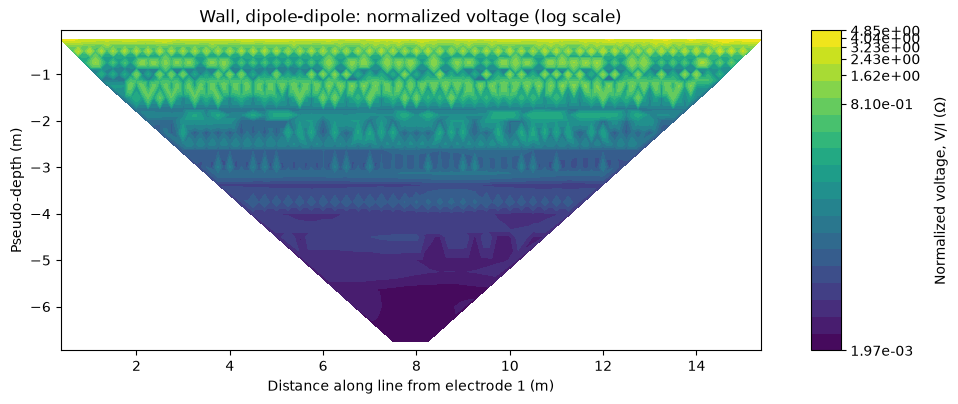

In [4]:
# or even better, plot them on a log-scale!
levels = np.logspace(
    np.log10(norm_v.min()),
    np.log10(norm_v.max()),
    20
) # contour levels are spaced logarithmically
norm = mpl.colors.LogNorm()  # and use a log-normalized colormapping between data values and color.
ax, im = static_utils.plot_pseudosection(
    survey, norm_v, cbar_label=r'Normalized voltage, V/I ($\Omega$)',
    contourf_opts={'levels':levels, 'norm':norm}
)
ax.set_xlabel('Distance along line from electrode 1 (m)')
ax.set_ylabel('Pseudo-depth (m)')
ax.set_title('Wall, dipole-dipole: normalized voltage (log scale)')

Text(0.5, 1.0, 'Wall, dipole-dipole: apparent resistivity')

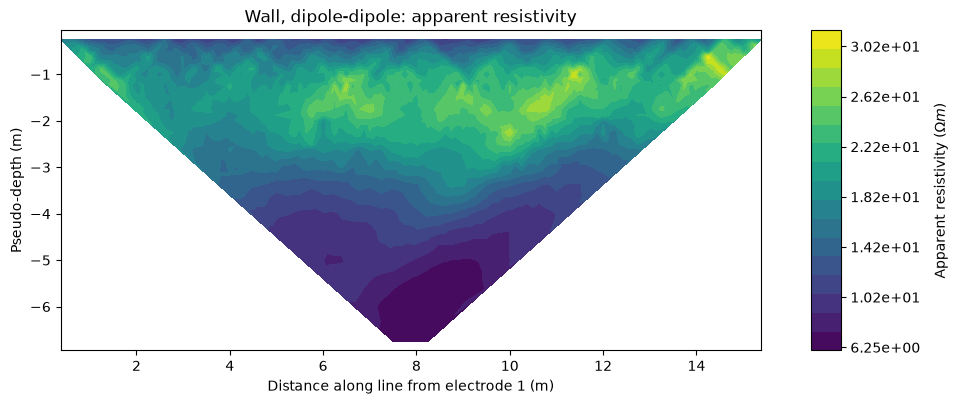

In [5]:
# More relevant though are the apparent resistivities (or conductivities)
rho_app = static_utils.apparent_resistivity_from_voltage(survey, norm_v)

ax, im = static_utils.plot_pseudosection(
    survey, rho_app, cbar_label=r'Apparent resistivity $(\Omega m)$',
    contourf_opts={'levels':20}
)
ax.set_xlabel('Distance along line from electrode 1 (m)')
ax.set_ylabel('Pseudo-depth (m)')
ax.set_title('Wall, dipole-dipole: apparent resistivity')

Text(0.5, 1.0, 'Wall, dipole-dipole: apparent resistivity (log scale)')

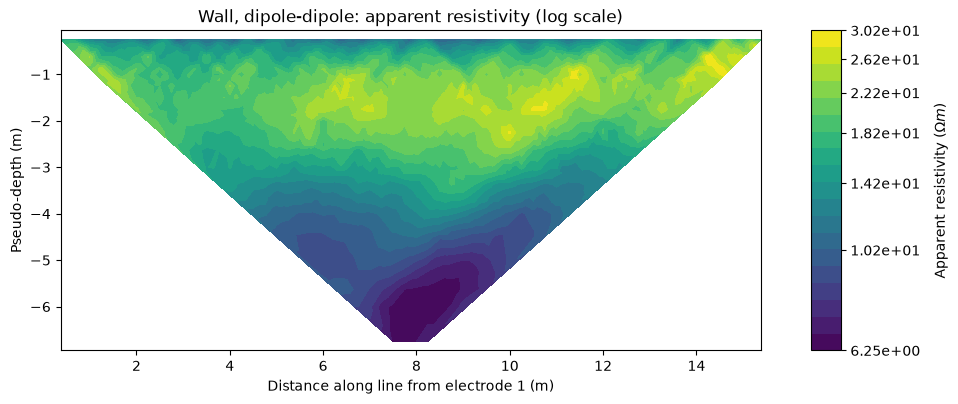

In [6]:
# or even better again, on a log-scale
levels = np.logspace(
    np.log10(rho_app.min()),
    np.log10(rho_app.max()),
    20
)
norm = mpl.colors.LogNorm()

ax, im = static_utils.plot_pseudosection(
    survey, rho_app, cbar_label=r'Apparent resistivity $(\Omega m)$',
    contourf_opts={'levels':levels, 'norm':norm}
)
ax.set_xlabel('Distance along line from electrode 1 (m)')
ax.set_ylabel('Pseudo-depth (m)')
ax.set_title('Wall, dipole-dipole: apparent resistivity (log scale)')

### A note on color normalization:
I've shown two ways of mapping the values of the data to colors in the colormap. By default matplotlib will use a
simple linear mapping between the data values and the colors on the colormap. This works well when the data your plotting vary on a linear scale.

But generally resistivity data varies by several orders of magnitude, and the relative difference between two values is what is important. For example, the difference in resistivity between a 1E-2 $\Omega m$ value and a 1 $\Omega m$ value has just as much impact on our data as the difference between 1E-4 $\Omega m$ and 1E-2 $\Omega m$.

Thus you will almost always see resistivity(conductivity) plotted on logarithmic colorscales. This can either be done by transforming the data using `np.log10(data)` before plotting it, or (and this is my recommended pathway) by using a `matplotlib.colors.LogNorm()` color normalizer, because it naturally makes the labeled values on the colormap consistent with the data.

### Step 3: zoom in on the walls
The full pseudosection goes much deeper than the walls, and a few large values at the ends of the line stretch the colour scale. Change the values between the dashed lines to explore the data:
* `max_depth` crops the plot to the top part of the pseudosection, where the walls are.
* `rho_min` and `rho_max` set the colour scale. Values outside this range are shown in the end colours, marked by the arrows on the colourbar. Narrowing the range makes small differences easier to see. The values set here are a reasonable place to start.

The colour scale is still logarithmic, as in the last plot.

To save a figure for your report, add `fig.savefig('wall_dipoledipole.png', dpi=200, bbox_inches='tight')` at the end of the cell.

Text(0.5, 1.0, 'Archaeological wall, dipole-dipole')

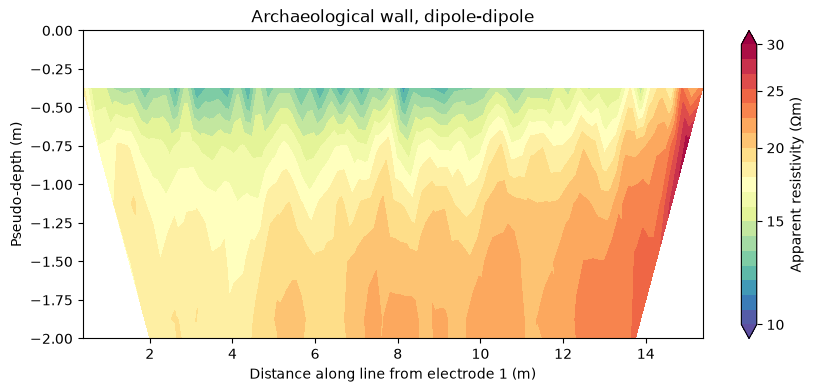

In [18]:
# ---- change these to explore the data ----
max_depth = 2.0       # m, deepest pseudo-depth to show (use 10 to see all of it)
rho_min = 10          # ohm m, bottom of the colour scale (rho_app.min() gives the full range)
rho_max = 30          # ohm m, top of the colour scale (rho_app.max() gives the full range)
n_levels = 20         # number of colour bands
cmap = 'Spectral_r'   # try 'viridis', 'RdYlBu_r', or 'plasma, or  'Spectral_r' ... or... 'jet'(!) on the orginal lab, we are using viridis
title = 'Archaeological wall, dipole-dipole'
# -------------------------------------------

levels = np.logspace(np.log10(rho_min), np.log10(rho_max), n_levels)
norm = mpl.colors.LogNorm(vmin=rho_min, vmax=rho_max)

fig, ax = plt.subplots(figsize=(10, 4))
ax, im = static_utils.plot_pseudosection(
    survey, rho_app, ax=ax, create_colorbar=False,
    contourf_opts={'levels': levels, 'norm': norm, 'cmap': cmap, 'extend': 'both'}
)

# build the colourbar ourselves so it follows rho_min and rho_max
cb = fig.colorbar(im, ax=ax)
ticks = np.linspace(rho_min, rho_max, 5)
cb.set_ticks(ticks)
cb.set_ticklabels([f'{t:.3g}' for t in ticks])
cb.ax.minorticks_off()
cb.set_label(r'Apparent resistivity ($\Omega$m)')

ax.set_ylim(-max_depth, 0)    # SimPEG plots pseudo-depth as negative (downward)
ax.set_xlabel('Distance along line from electrode 1 (m)')
ax.set_ylabel('Pseudo-depth (m)')
ax.set_title(title)

## Wenner survey over the archaeological wall
Repeat the same steps for the Wenner survey.

In [8]:
filename = 'data2026/Wenner_1-2023-03-08-123545.dat'

with open(filename) as f:
    lines = f.readlines()
n_data = int(lines[6])     # line 7 of the file gives the number of readings
d = np.array([line.split() for line in lines[9:9 + n_data]], dtype=float)  # readings start on line 10
print(n_data, 'readings')

A = d[:, 1:3]    # (x, z) of the A electrode for every reading, an (n_data, 2) array
B = d[:, 3:5]
M = d[:, 5:7]
N = d[:, 7:9]

# Create a simpeg "survey" from these locations:
# The survey will not necessarily be in the same order as the
# ABMN values you supplied, but it will helpfully also return an array you
# can use to re-arrange your data that corresponds to the survey.
survey, sort_index = static_utils.generate_survey_from_abmn_locations(
    locations_a=A, locations_b=B, locations_m=M, locations_n=N,
    data_type='volt', output_sorting=True
)

norm_v = d[:, 9][sort_index]   # the normalized voltage column (V/I, in ohms)

651 readings


Text(0.5, 1.0, 'Wall, Wenner: normalized voltage')

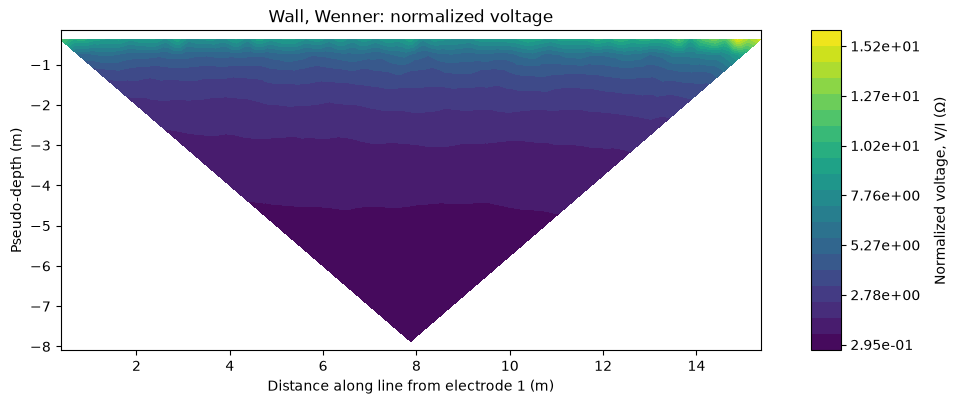

In [9]:
# can plot the normalized voltages
ax, im = static_utils.plot_pseudosection(
    survey, norm_v, cbar_label=r'Normalized voltage, V/I ($\Omega$)',
    contourf_opts={'levels':20}
)
ax.set_xlabel('Distance along line from electrode 1 (m)')
ax.set_ylabel('Pseudo-depth (m)')
ax.set_title('Wall, Wenner: normalized voltage')

Text(0.5, 1.0, 'Wall, Wenner: normalized voltage (log scale)')

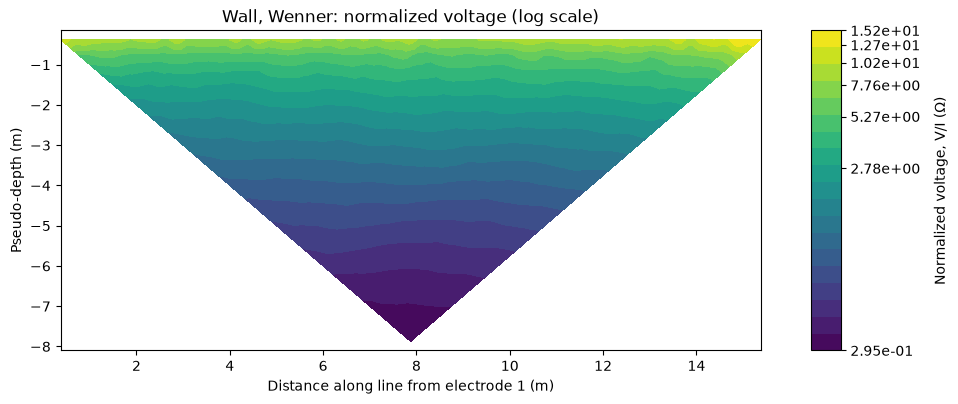

In [10]:
# or even better, plot them on a log-scale!
levels = np.logspace(
    np.log10(norm_v.min()),
    np.log10(norm_v.max()),
    20
) # contour levels are spaced logarithmically
norm = mpl.colors.LogNorm()  # and use a log-normalized colormapping between data values and color.
ax, im = static_utils.plot_pseudosection(
    survey, norm_v, cbar_label=r'Normalized voltage, V/I ($\Omega$)',
    contourf_opts={'levels':levels, 'norm':norm}
)
ax.set_xlabel('Distance along line from electrode 1 (m)')
ax.set_ylabel('Pseudo-depth (m)')
ax.set_title('Wall, Wenner: normalized voltage (log scale)')

Text(0.5, 1.0, 'Wall, Wenner: apparent resistivity')

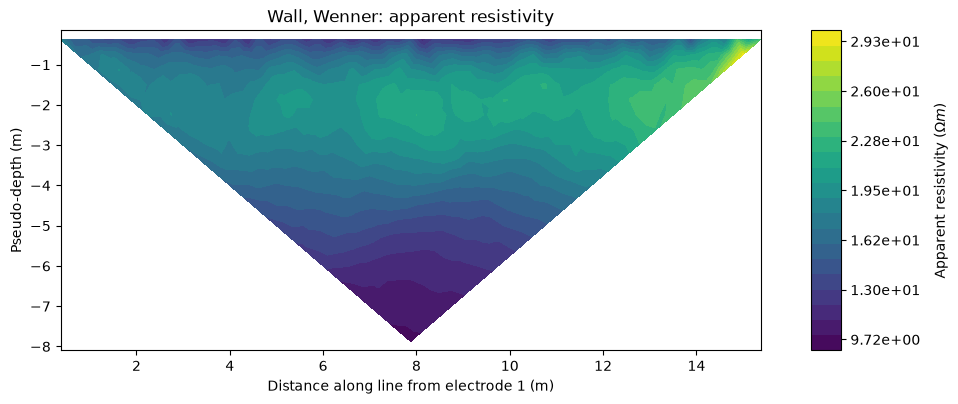

In [11]:
# More relevant though are the apparent resistivities (or conductivities)
rho_app = static_utils.apparent_resistivity_from_voltage(survey, norm_v)

ax, im = static_utils.plot_pseudosection(
    survey, rho_app, cbar_label=r'Apparent resistivity $(\Omega m)$',
    contourf_opts={'levels':20}
)
ax.set_xlabel('Distance along line from electrode 1 (m)')
ax.set_ylabel('Pseudo-depth (m)')
ax.set_title('Wall, Wenner: apparent resistivity')

Text(0.5, 1.0, 'Wall, Wenner: apparent resistivity (log scale)')

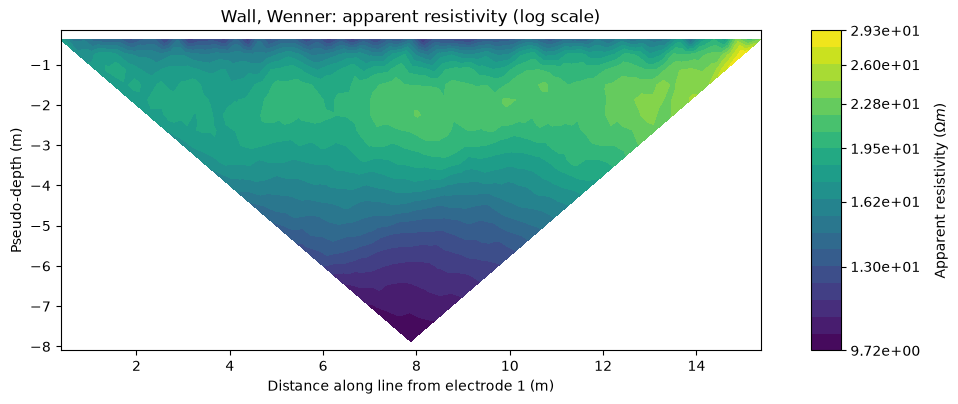

In [12]:
# or even better again, on a log-scale
levels = np.logspace(
    np.log10(rho_app.min()),
    np.log10(rho_app.max()),
    20
)
norm = mpl.colors.LogNorm()

ax, im = static_utils.plot_pseudosection(
    survey, rho_app, cbar_label=r'Apparent resistivity $(\Omega m)$',
    contourf_opts={'levels':levels, 'norm':norm}
)
ax.set_xlabel('Distance along line from electrode 1 (m)')
ax.set_ylabel('Pseudo-depth (m)')
ax.set_title('Wall, Wenner: apparent resistivity (log scale)')

Text(0.5, 1.0, 'Archaeological wall, Wenner')

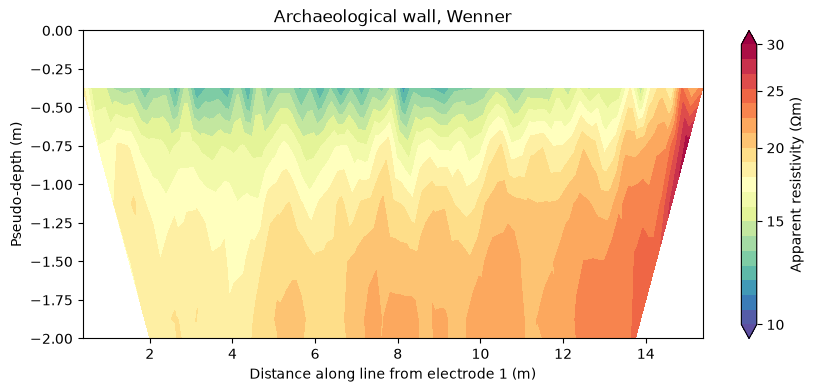

In [13]:
# ---- change these to explore the data ----
max_depth = 2.0       # m, deepest pseudo-depth to show
rho_min = 10          # ohm m, bottom of the colour scale (rho_app.min() gives the full range)
rho_max = 30          # ohm m, top of the colour scale (rho_app.max() gives the full range)
n_levels = 20         # number of colour bands
cmap = 'Spectral_r'   # try 'viridis', 'RdYlBu_r', or 'plasma, or  'Spectral_r' ... or... 'jet'(!) on the orginal lab, we are using viridis
title = 'Archaeological wall, Wenner'
# -------------------------------------------

levels = np.logspace(np.log10(rho_min), np.log10(rho_max), n_levels)
norm = mpl.colors.LogNorm(vmin=rho_min, vmax=rho_max)

fig, ax = plt.subplots(figsize=(10, 4))
ax, im = static_utils.plot_pseudosection(
    survey, rho_app, ax=ax, create_colorbar=False,
    contourf_opts={'levels': levels, 'norm': norm, 'cmap': cmap, 'extend': 'both'}
)

# build the colourbar ourselves so it follows rho_min and rho_max
cb = fig.colorbar(im, ax=ax)
ticks = np.linspace(rho_min, rho_max, 5)
cb.set_ticks(ticks)
cb.set_ticklabels([f'{t:.3g}' for t in ticks])
cb.ax.minorticks_off()
cb.set_label(r'Apparent resistivity ($\Omega$m)')

ax.set_ylim(-max_depth, 0)    # SimPEG plots pseudo-depth as negative (downward)
ax.set_xlabel('Distance along line from electrode 1 (m)')
ax.set_ylabel('Pseudo-depth (m)')
ax.set_title(title)

### Optional: see the artefact for yourself
If you are curious, load the dipole-dipole `.txt` file, build the survey from its rounded positions as you did in Lab 10, and plot it with the same `max_depth`, `rho_min` and `rho_max`. Compare it with your plot above. What do you notice, and how far apart are the stripes? **This is not a deliverable question, just something to think about**